In [5]:
import os
try:
    from google.colab import drive; drive.mount('/content/drive')
    OUT = '/content/drive/MyDrive/ood_v2'
except ImportError:
    OUT = os.path.abspath('./ood_out')
os.makedirs(OUT, exist_ok=True)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [6]:
import os, time, math, json, warnings
import numpy as np, pandas as pd, torch, torch.nn as nn, torch.nn.functional as F
from sklearn.datasets import fetch_openml
from sklearn.model_selection import train_test_split, cross_val_predict
from sklearn.preprocessing import QuantileTransformer, OneHotEncoder, LabelEncoder
from sklearn.metrics import roc_auc_score
from sklearn.feature_selection import mutual_info_classif
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.covariance import MinCovDet
warnings.filterwarnings('ignore')
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu'); print('device:', device)

QUICK = False
sfx = '_v2' + ('_quick' if QUICK else '')      # v1 CSVs are NOT compatible, don't mix
CFG = dict(datasets=['otto','jannis','adult','higgs'], seeds=(0,1,2,3,4), K=32, d_block=256, n_blocks=3, dropout=0.1,
           max_epochs=100, patience=12, bs=1024, clip=1.0, weight_decay=1e-4, lr_grid=(3e-4,1e-3,3e-3),
           hold_folds=3, tail_q=0.8, perturb_scales=(0.5,1.0,2.0,3.0), perturb_frac=0.25, ood_cap=15000, alphas=(0.01,0.05,0.10),
           res_path=f'{OUT}/ood_results{sfx}.csv', acc_path=f'{OUT}/ood_acc{sfx}.csv',
           ceil_path=f'{OUT}/ood_ceiling{sfx}.csv', lr_path=f'{OUT}/ood_lr{sfx}.json')
FAST = True     # 3 seeds, 60 epochs; set False for the final run
if FAST: CFG.update(seeds=(0,1,2), max_epochs=60, patience=8)
if QUICK: CFG.update(datasets=['adult'], seeds=(0,), max_epochs=15, lr_grid=(1e-3,3e-3))

# freeze BEFORE looking at v2 results
PREREG = ['IN-Maha-global','IN-kNN-nrm-k20','LAT-Maha-class','LAT-RMD','LAT-kNN-nrm-k20','LAT-LDR-nrm-k5',
          'LOGIT-MSP','LOGIT-Energy','LOGIT-MI']

device: cuda


In [7]:
SRC = {'otto': (45548, 'Otto-Group-Product-Classification-Challenge'), 'jannis': (41168, 'jannis'),
       'adult': (1590, 'adult'), 'higgs': (23512, 'higgs')}

import requests

def _find_openml_id(name):
    for q in (name, name.lower(), 'otto-group-product-classification-challenge', 'Otto-Group-Product-Classification-Challenge'):
        try:
            r = requests.get(f'https://www.openml.org/api/v1/json/data/list/data_name/{q}/status/active', timeout=30).json()
            ds = r['data']['dataset']
            if ds: return int(max(ds, key=lambda d: d.get('NumberOfInstances', 0))['did'])
        except Exception: continue
    return None

def load_dataset(name):
    did, nm = SRC[name]
    try: b = fetch_openml(data_id=did, as_frame=True, parser='auto')
    except Exception as e:
        print(f'[{name}] data_id {did} failed; searching OpenML by name')
        did2 = _find_openml_id(nm)
        if did2 is None: raise RuntimeError(f'{name}: not found on OpenML, upload a CSV instead (see below)') from e
        print(f'[{name}] using data_id {did2}'); b = fetch_openml(data_id=did2, as_frame=True, parser='auto')
    X, y = b.data.copy(), b.target
    X = X.drop(columns=[c for c in X.columns if str(c).lower() == 'id'])
    cat_cols = [c for c in X.columns if str(X[c].dtype) in ('category', 'object')]
    num_cols = [c for c in X.columns if c not in cat_cols]
    for c in cat_cols: X[c] = X[c].astype(object).where(X[c].notna(), 'missing').astype(str)
    for c in num_cols: X[c] = pd.to_numeric(X[c], errors='coerce'); X[c] = X[c].fillna(X[c].median())
    return X.reset_index(drop=True), LabelEncoder().fit_transform(y.astype(str)).astype(np.int64), num_cols, cat_cols

def make_partition(y, seed=0):                 # 0 train 60% | 1 val 10% | 2 calibration 10% | 3 test 20%   (CHANGED: now called once per seed)
    idx = np.arange(len(y))
    tr, rest = train_test_split(idx, test_size=0.4, stratify=y, random_state=seed)
    va, rest2 = train_test_split(rest, test_size=0.75, stratify=y[rest], random_state=seed)
    ca, te = train_test_split(rest2, test_size=2/3, stratify=y[rest2], random_state=seed)
    part = np.empty(len(y), int); part[tr], part[va], part[ca], part[te] = 0, 1, 2, 3
    return part

DATA, TAILFEATS = {}, {}
for nm in CFG['datasets']:
    X, y, num_cols, cat_cols = load_dataset(nm)
    DATA[nm] = dict(X=X, y=y, num_cols=num_cols, cat_cols=cat_cols)          # no 'part' here any more
    part0 = make_partition(y, 0); trm = part0 == 0; cands = []
    for c in num_cols:
        if X[c].nunique() <= 10: continue
        if (X[c].values > np.quantile(X.loc[trm, c].values, CFG['tail_q'])).mean() >= 0.1: cands.append(c)
    if cands:
        idx = np.random.default_rng(0).permutation(np.where(trm)[0])[:20000]
        mi = mutual_info_classif(X.loc[idx, cands].values, y[idx], random_state=0)
        TAILFEATS[nm] = [cands[int(i)] for i in np.argsort(-mi)[:2]]   # [0]=eval tail, [1]=dev tail 'tailB'
    print(nm, X.shape, np.bincount(y).tolist(), TAILFEATS.get(nm))

def build_contexts(name, part, seed):
    d = DATA[name]; X, y = d['X'], d['y']; n = len(y)
    ctxs = [dict(name='full', idmask=np.ones(n, bool))]
    classes, counts = np.unique(y, return_counts=True)
    if len(classes) > 2:
        order = np.argsort(counts)
        for p in np.unique(np.round(np.linspace(0, len(order)-1, CFG['hold_folds'])).astype(int)):
            c = int(classes[order[p]]); ctxs.append(dict(name=f'hold{c}', idmask=(y != c), oodmask=(y == c), ood_name='heldout'))
    trm = part == 0
    for f, tag in zip(TAILFEATS.get(name, []), ('tail', 'tailB')):
        idm = X[f].values <= np.quantile(X.loc[trm, f].values, CFG['tail_q'])
        ctxs.append(dict(name=f'{tag}[{f}]', idmask=idm, oodmask=~idm, ood_name=tag, linear_cols=[f]))
    return ctxs

otto (61878, 93) [1929, 16122, 8004, 2691, 2739, 14135, 2839, 8464, 4955] ['feat_11', 'feat_25']
jannis (83733, 54) [1687, 28790, 14734, 38522] ['V22', 'V23']
adult (48842, 14) [37155, 11687] ['age', 'hours-per-week']
higgs (98050, 28) [46223, 51827] ['m_bb', 'm_wbb']


In [13]:
def preprocess(name, ctx, part):
    d = DATA[name]; X = d['X']; trm = (part == 0) & ctx['idmask']
    num = X[d['num_cols']].values.astype(np.float64)
    qt = QuantileTransformer(n_quantiles=min(1000, int(trm.sum())), output_distribution='normal', random_state=0).fit(num[trm])
    Z = qt.transform(num)
    for c in ctx.get('linear_cols', []):       # keep extrapolation visible on the shifted feature
        j = d['num_cols'].index(c); Z[:, j] = (num[:, j] - num[trm, j].mean()) / (num[trm, j].std() + 1e-8)
    parts = [Z]
    if d['cat_cols']:
        try: ohe = OneHotEncoder(handle_unknown='ignore', sparse_output=False)
        except TypeError: ohe = OneHotEncoder(handle_unknown='ignore', sparse=False)
        cat = X[d['cat_cols']]; ohe.fit(cat[trm]); parts.append(ohe.transform(cat))
    return np.hstack(parts).astype(np.float32), len(d['num_cols'])     # numeric columns come first

def perturb_sets(Xte, n_num, seed=0):          # the perturbed columns and their signs now change with the seed
    rng = np.random.default_rng(seed); m = max(1, math.ceil(CFG['perturb_frac'] * n_num))
    cols = rng.choice(n_num, m, replace=False); sign = rng.choice([-1.0, 1.0], m)    # fixed direction per feature = systematic drift
    out = {}
    for s in CFG['perturb_scales']:
        A = Xte.copy(); A[:, cols] += (s * sign).astype(np.float32); out[f'perturb_s{s}'] = A
    return out

def separability(Xid, Xood, n=3000, seed=0):  # cross-validated ID-vs-OOD AUROC in input space: rough ceiling for input-based detectors
    r = np.random.default_rng(seed)
    a = Xid[r.choice(len(Xid), min(n, len(Xid)), replace=False)]; b = Xood[r.choice(len(Xood), min(n, len(Xood)), replace=False)]
    Z = np.vstack([a, b]); t = np.r_[np.zeros(len(a)), np.ones(len(b))]
    p = cross_val_predict(HistGradientBoostingClassifier(max_iter=100, random_state=seed), Z, t, cv=3, method='predict_proba')[:, 1]
    return roc_auc_score(t, p)

In [14]:
class LinearEnsemble(nn.Module):
    def __init__(self, d_in, d_out, k):
        super().__init__()
        self.weight = nn.Parameter(torch.empty(k, d_out, d_in)); self.bias = nn.Parameter(torch.zeros(k, d_out))
        for i in range(k): nn.init.kaiming_uniform_(self.weight[i], a=5**0.5)
    def forward(self, x): return torch.einsum('bki,koi->bko', x, self.weight) + self.bias

class BELinear(nn.Module):                     # BatchEnsemble layer: shared W, per-member R (input), S (output), B (bias)
    def __init__(self, d_in, d_out, k, signs_R):
        super().__init__()
        self.W = nn.Linear(d_in, d_out, bias=False)
        R = (torch.randint(0, 2, (k, d_in)).float() * 2 - 1) if signs_R else torch.ones(k, d_in)
        self.R, self.S, self.B = nn.Parameter(R), nn.Parameter(torch.ones(k, d_out)), nn.Parameter(torch.zeros(k, d_out))
    def forward(self, x): return self.W(x * self.R) * self.S + self.B

class TabMNet(nn.Module):
    def __init__(self, d_in, n_classes, k, d_block, n_blocks, dropout):
        super().__init__(); self.k = k; blocks, d = [], d_in
        for i in range(n_blocks):
            blocks.append(nn.Sequential(BELinear(d, d_block, k, i == 0), nn.ReLU(), nn.Dropout(dropout))); d = d_block
        self.blocks = nn.ModuleList(blocks); self.head = LinearEnsemble(d, n_classes, k)
    def forward(self, x):                      # -> logits (B,K,C), last-block embedding (B,K,D)
        h = x.unsqueeze(1).expand(-1, self.k, -1)
        for b in self.blocks: h = b(h)
        return self.head(h), h

class MLPNet(nn.Module):                       # same API, K = 1  (=> mutual information is identically 0, see logit_scores)
    def __init__(self, d_in, n_classes, d_block, n_blocks, dropout):
        super().__init__(); layers, d = [], d_in
        for _ in range(n_blocks): layers += [nn.Linear(d, d_block), nn.ReLU(), nn.Dropout(dropout)]; d = d_block
        self.backbone = nn.Sequential(*layers); self.head = nn.Linear(d, n_classes)
    def forward(self, x):
        h = self.backbone(x).unsqueeze(1); return self.head(h), h

@torch.no_grad()
def infer(model, X, bs=4096):                  # logits (N,K,C) and member-averaged embedding (N,D)
    model.eval(); L, E = [], []
    for i in range(0, len(X), bs):
        lg, h = model(torch.as_tensor(X[i:i + bs], dtype=torch.float32, device=device)); L.append(lg.cpu()); E.append(h.mean(1).cpu())
    return torch.cat(L), torch.cat(E).numpy()

def ens_nll(lg, y): return F.nll_loss(torch.log(F.softmax(lg, -1).mean(1) + 1e-12), y).item()

def train_net(arch, Xtr, ytr, Xva, yva, n_classes, seed, lr):
    torch.manual_seed(seed); np.random.seed(seed); d_in = Xtr.shape[1]
    model = (TabMNet(d_in, n_classes, CFG['K'], CFG['d_block'], CFG['n_blocks'], CFG['dropout']) if arch == 'tabm'
             else MLPNet(d_in, n_classes, CFG['d_block'], CFG['n_blocks'], CFG['dropout'])).to(device)
    opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=CFG['weight_decay'])
    Xd, yd, yv = torch.tensor(Xtr, device=device), torch.tensor(ytr, device=device), torch.tensor(yva)
    best, bad, best_state = float('inf'), 0, None
    for ep in range(CFG['max_epochs']):
        model.train(); perm = torch.randperm(len(Xd), device=device)
        for i in range(0, len(Xd), CFG['bs']):
            idx = perm[i:i + CFG['bs']]; lg, _ = model(Xd[idx])
            loss = F.cross_entropy(lg.reshape(-1, n_classes), yd[idx].repeat_interleave(lg.shape[1]))   # per-member loss
            opt.zero_grad(); loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), CFG['clip']); opt.step()                # gradient clipping restored
        nll = ens_nll(infer(model, Xva)[0], yv)
        if nll < best - 1e-5: best, bad, best_state = nll, 0, {n: t.detach().clone() for n, t in model.state_dict().items()}
        else:
            bad += 1
            if bad >= CFG['patience']: break
    model.load_state_dict(best_state)
    vacc = (F.softmax(infer(model, Xva)[0], -1).mean(1).argmax(-1).numpy() == yva).mean()
    assert vacc > np.bincount(yva).max() / len(yva) + 0.02, f'{arch} did not beat the majority baseline (val acc {vacc:.3f})'
    return model, float(vacc), float(best)

In [15]:
def l2n(A): return A / (np.linalg.norm(A, axis=1, keepdims=True) + 1e-12)

@torch.no_grad()
def knn_search(A_gpu, Q, kmax, drop_first=False, bs=2048):
    Qt = torch.as_tensor(Q, dtype=torch.float32); kk = kmax + int(drop_first); Dl, Il = [], []
    for i in range(0, len(Qt), bs):
        v, ix = torch.cdist(Qt[i:i + bs].to(device), A_gpu).topk(kk, largest=False)
        if drop_first: v, ix = v[:, 1:], ix[:, 1:]          # train queries: drop the point itself
        Dl.append(v.cpu()); Il.append(ix.cpu())
    return torch.cat(Dl).numpy(), torch.cat(Il).numpy()

class Bank:
    KS = {'nrm': (5, 20), 'raw': (5,)}
    def __init__(self, Ftr, ytr, ridge=1e-3):
        E = Ftr.astype(np.float64); self.D = D = E.shape[1]; self.ridge = ridge
        self.mu = E.mean(0); sd = E.std(0); self.sd = np.maximum(sd, 0.05*np.median(sd) + 1e-8)
        Z = E - self.mu; C0 = Z.T @ Z / len(Z); self.P0 = self._inv(C0)
        w, V = np.linalg.eigh(C0); self.V = V[:, np.argsort(w)[::-1]]
        cl = np.unique(ytr); self.mus = np.stack([E[ytr == c].mean(0) for c in cl])
        Zw = E - self.mus[np.searchsorted(cl, ytr)]; self.Pw = self._inv(Zw.T @ Zw / len(Zw))
        self.rs = [r for r in (8,) if r < D]; self.knn = {}
        for sp in self.KS:
            A = self._space(E, sp); Ag = torch.tensor(A, dtype=torch.float32, device=device)
            dtr, _ = knn_search(Ag, A, max(self.KS[sp]), drop_first=True)
            self.knn[sp] = dict(A=Ag, trk={k: dtr[:, k-1] for k in self.KS[sp]})
    def _inv(self, C): return np.linalg.inv(C + self.ridge*np.trace(C)/self.D*np.eye(self.D))
    def _space(self, E, sp): return l2n(E).astype(np.float32) if sp == 'nrm' else E.astype(np.float32)
    def score(self, Q):
        E = Q.astype(np.float64); Z = E - self.mu; out = {}
        out['Euc-mean-z'] = np.linalg.norm(Z/self.sd, axis=1)
        out['Maxabs-z'] = np.abs(Z/self.sd).max(1)                      # new one-feature reference
        d0 = ((Z @ self.P0)*Z).sum(1); out['Maha-global'] = np.sqrt(np.maximum(d0, 0))
        dc = np.stack([(((E-m) @ self.Pw)*(E-m)).sum(1) for m in self.mus], 1).min(1)
        out['Maha-class'] = np.sqrt(np.maximum(dc, 0)); out['RMD'] = dc - d0
        P2 = (Z @ self.V)**2; tot = (Z*Z).sum(1)
        for r in self.rs: out[f'PCAres-r{r}'] = np.sqrt(np.maximum(tot - P2[:, :r].sum(1), 0))
        for sp, ks in self.KS.items():
            dq, iq = knn_search(self.knn[sp]['A'], self._space(E, sp), max(ks))
            for k in ks: out[f'kNN-{sp}-k{k}'] = dq[:, k-1]
            if sp == 'nrm': out['LDR-nrm-k5'] = dq[:, 4] / (self.knn[sp]['trk'][5][iq[:, :5]].mean(1) + 1e-12)
        return out

In [16]:
def clean(a): return np.nan_to_num(np.asarray(a, dtype=np.float64), nan=0.0, posinf=1e12, neginf=-1e12)
def auroc(neg, pos): return roc_auc_score(np.r_[np.zeros(len(neg)), np.ones(len(pos))], np.r_[neg, pos])
def conf_thr(cal, a):                          # split-conformal quantile: ID flag rate <= a under exchangeability
    n = len(cal); k = min(n, int(math.ceil((n + 1) * (1 - a)))); return np.sort(cal)[k - 1]

def metrics_rows(base, scores, onames):        # scores: {detector: {query_name: array}}
    rows = []
    for det, sq in scores.items():
        cal, te = clean(sq['cal']), clean(sq['test']); thr = {a: conf_thr(cal, a) for a in CFG['alphas']}
        for on in onames:
            so = clean(sq[on])
            r = dict(base, detector=det, ood=on, AUROC=auroc(te, so), FPR95=float((te >= np.quantile(so, 0.05)).mean()))
            for a, t in thr.items():
                r[f'TPR{int(round(a*100)):02d}'] = float((so > t).mean()); r[f'rFPR{int(round(a*100)):02d}'] = float((te > t).mean())
            rows.append(r)
    return rows

def logit_scores(lg):
    p = F.softmax(lg, -1); pm = p.mean(1); ent = lambda q: -(q*torch.log(q+1e-12)).sum(-1)
    out = {'LOGIT-MSP': -pm.max(-1).values.numpy(), 'LOGIT-Energy': -torch.logsumexp(lg, -1).mean(1).numpy()}
    if lg.shape[1] > 1: out['LOGIT-MI'] = (ent(pm) - ent(p).mean(1)).numpy()
    return out

def bank_scores(bank, EM, prefix):
    per_q = {qn: bank.score(E) for qn, E in EM.items()}
    return {f'{prefix}-{det}': {qn: per_q[qn][det] for qn in EM} for det in per_q['test']}

def save_rows(rows, path):
    if rows: pd.DataFrame(rows).to_csv(path, mode='a', header=not os.path.exists(path), index=False)

def get_split(name, ctx, part):
    Xall, n_num = preprocess(name, ctx, part); idm = ctx['idmask']
    tr, va, ca, te = [np.where((part == p) & idm)[0] for p in (0,1,2,3)]
    return Xall, n_num, tr, va, ca, te

def tune_lr(name, arch):                       # same grid for TabM and MLP, chosen by val NLL
    cache = json.load(open(CFG['lr_path'])) if os.path.exists(CFG['lr_path']) else {}
    key = f'{name}|{arch}'
    if key in cache: return cache[key]['lr']
    y = DATA[name]['y']; C = int(y.max()+1); s0 = CFG['seeds'][0]; part = make_partition(y, s0)
    Xall, _, tr, va, _, _ = get_split(name, build_contexts(name, part, s0)[0], part); res = {}
    for lr in CFG['lr_grid']:
        try: _, _, nll = train_net(arch, Xall[tr], y[tr], Xall[va], y[va], C, s0, lr)
        except AssertionError: nll = float('inf')
        res[lr] = nll; print(f'  [lr] {name}/{arch} {lr:g} NLL={nll:.4f}'); torch.cuda.empty_cache()
    best = min(res, key=res.get); cache[key] = dict(lr=best, val_nll={str(k): v for k, v in res.items()})
    json.dump(cache, open(CFG['lr_path'], 'w'), indent=1); return best

def run_all():
    done = set(map(tuple, pd.read_csv(CFG['res_path'], usecols=['dataset','ctx','arch','seed']).drop_duplicates().values.tolist())) if os.path.exists(CFG['res_path']) else set()
    cdone = set(map(tuple, pd.read_csv(CFG['ceil_path'])[['dataset','ctx','ood','seed']].values.tolist())) if os.path.exists(CFG['ceil_path']) else set()
    T0 = time.time()
    for name in CFG['datasets']:
        y = DATA[name]['y']; C = int(y.max()+1); LR = {a: tune_lr(name, a) for a in ('tabm','mlp')}
        for seed in CFG['seeds']:
            part = make_partition(y, seed)
            for ctx in build_contexts(name, part, seed):
                Xall, n_num, tr, va, ca, te = get_split(name, ctx, part)
                if ctx['name'] == 'full': oods = perturb_sets(Xall[te], n_num, seed)
                else:
                    oi = np.where(ctx['oodmask'])[0]; oi = np.random.default_rng(seed).choice(oi, min(len(oi), CFG['ood_cap']), replace=False)
                    oods = {ctx['ood_name']: Xall[oi]}
                Q = {'cal': Xall[ca], 'test': Xall[te], **oods}; onames = list(oods); base = dict(dataset=name, ctx=ctx['name'])
                print(f"== {name}/{ctx['name']} seed={seed} [{time.time()-T0:.0f}s]")
                crow = [dict(base, ood=on, seed=seed, ceiling=separability(Q['test'], Q[on], seed=seed)) for on in onames if (name, ctx['name'], on, seed) not in cdone]
                save_rows(crow, CFG['ceil_path'])
                if (name, ctx['name'], 'input', seed) not in done:           # input baseline: once PER SEED now
                    bank = Bank(Xall[tr], y[tr]); sc = bank_scores(bank, Q, 'IN')
                    save_rows(metrics_rows(dict(base, arch='input', seed=seed), sc, onames), CFG['res_path']); del bank; torch.cuda.empty_cache()
                for arch in ('tabm','mlp'):
                    if (name, ctx['name'], arch, seed) in done: continue
                    model, vacc, _ = train_net(arch, Xall[tr], y[tr], Xall[va], y[va], C, seed, LR[arch])
                    LG, EM = {}, {}
                    for qn, Xq in Q.items(): LG[qn], EM[qn] = infer(model, Xq)
                    etr = infer(model, Xall[tr])[1]; bank = Bank(etr, y[tr]); sc = bank_scores(bank, EM, 'LAT')
                    LS = {qn: logit_scores(LG[qn]) for qn in Q}; sc.update({k: {qn: LS[qn][k] for qn in Q} for k in LS['test']})
                    tacc = float((F.softmax(LG['test'], -1).mean(1).argmax(-1).numpy() == y[te]).mean())
                    save_rows([dict(base, arch=arch, seed=seed, lr=LR[arch], val_acc=vacc, test_acc=tacc)], CFG['acc_path'])
                    save_rows(metrics_rows(dict(base, arch=arch, seed=seed), sc, onames), CFG['res_path'])
                    del bank, model; torch.cuda.empty_cache()
    print('finished.')

In [17]:
run_all()

  [lr] otto/tabm 0.0003 NLL=0.6359
  [lr] otto/tabm 0.001 NLL=0.5875
  [lr] otto/tabm 0.003 NLL=0.5693
  [lr] otto/mlp 0.0003 NLL=0.5782
  [lr] otto/mlp 0.001 NLL=0.5759
  [lr] otto/mlp 0.003 NLL=0.5945
== otto/full seed=0 [164s]
== otto/hold0 seed=0 [244s]
== otto/hold8 seed=0 [307s]
== otto/hold1 seed=0 [366s]
== otto/tail[feat_11] seed=0 [416s]
== otto/tailB[feat_25] seed=0 [470s]
== otto/full seed=1 [517s]
== otto/hold0 seed=1 [598s]
== otto/hold8 seed=1 [660s]
== otto/hold1 seed=1 [718s]
== otto/tail[feat_11] seed=1 [767s]
== otto/tailB[feat_25] seed=1 [821s]
== otto/full seed=2 [876s]
== otto/hold0 seed=2 [957s]
== otto/hold8 seed=2 [1019s]
== otto/hold1 seed=2 [1079s]
== otto/tail[feat_11] seed=2 [1126s]
== otto/tailB[feat_25] seed=2 [1180s]
  [lr] jannis/tabm 0.0003 NLL=0.7015
  [lr] jannis/tabm 0.001 NLL=0.6718
  [lr] jannis/tabm 0.003 NLL=0.6602
  [lr] jannis/mlp 0.0003 NLL=0.7282
  [lr] jannis/mlp 0.001 NLL=0.7229
  [lr] jannis/mlp 0.003 NLL=0.7229
== jannis/full seed=0 [144

In [18]:
R = pd.read_csv(CFG['res_path'])
R = R[~((R.detector == 'LOGIT-MI') & (R.arch == 'mlp'))].copy()     # safeguard: K=1 MI is constant 0 (no longer produced, but drop it from any older file)
R['space'] = R.detector.str.split('-').str[0]; R['proto'] = R.ood.str.split('_').str[0]
ACC = pd.read_csv(CFG['acc_path']); CE = pd.read_csv(CFG['ceil_path']); CE['proto'] = CE.ood.str.split('_').str[0]
print(f"{len(R)} result rows | seeds per arch: {R.groupby('arch').seed.nunique().to_dict()} | detectors: {R.detector.nunique()}")

print('\nModel accuracy and chosen learning rate (the OOD analysis is only meaningful if these are sensible):')
acc = ACC.groupby(['dataset', 'ctx', 'arch']).agg(lr=('lr', 'first'), val_acc=('val_acc', 'mean'), test_acc=('test_acc', 'mean'), test_acc_sd=('test_acc', 'std')).round(4)
display(acc); acc.to_csv(f'{OUT}/summary_accuracy.csv')

def pick(ds, arch):                            # LAT/LOGIT rows from `arch`, IN rows from the (per-seed) model-free input baselines
    s = R[R.dataset == ds]
    return s[((s.space == 'IN') & (s.arch == 'input')) | ((s.space != 'IN') & (s.arch == arch))]

OODCOLS = ['perturb_s0.5', 'perturb_s1.0', 'perturb_s2.0', 'perturb_s3.0', 'heldout', 'tail', 'tailB']    # tailB = dev tail, used only for detector selection
def show_auroc(ds, arch='tabm'):
    s = pick(ds, arch).groupby(['detector', 'ood', 'seed']).AUROC.mean().reset_index()     # average folds inside a seed, then look across seeds
    g = s.groupby(['detector', 'ood']).AUROC.agg(['mean', 'std']).reset_index()
    m, sd = g.pivot(index='detector', columns='ood', values='mean'), g.pivot(index='detector', columns='ood', values='std')
    cols = [c for c in OODCOLS if c in m.columns]; t = m[cols].copy(); t['mean'] = t.mean(1); t['seed_sd'] = sd[cols].mean(1)
    display(t.sort_values('mean', ascending=False).round(3)); return t
for ds in CFG['datasets']:
    print(f'\n=== {ds}: AUROC, TabM embedding (LAT), input space (IN), logits (LOGIT); mean over seeds (and folds); seed_sd = typical across-seed sd ===')
    show_auroc(ds, 'tabm')

print('\nCalibration check: realised ID flag rate on the test set (targets 0.01 / 0.05 / 0.10)')
display(R.groupby(['space', 'arch'])[['rFPR01', 'rFPR05', 'rFPR10']].agg(['mean', 'min', 'max']).round(3))

3150 result rows | seeds per arch: {'input': 3, 'mlp': 3, 'tabm': 3} | detectors: 23

Model accuracy and chosen learning rate (the OOD analysis is only meaningful if these are sensible):


lr  val_acc  test_acc  test_acc_sd
dataset ctx                   arch                                        
adult   full                  mlp   0.0003   0.8587    0.8594       0.0029
                              tabm  0.0010   0.8593    0.8617       0.0024
        tailB[hours-per-week] mlp   0.0003   0.8781    0.8774       0.0030
                              tabm  0.0010   0.8780    0.8803       0.0041
        tail[age]             mlp   0.0003   0.8657    0.8701       0.0053
                              tabm  0.0010   0.8689    0.8716       0.0034
higgs   full                  mlp   0.0030   0.7175    0.7175       0.0022
                              tabm  0.0030   0.7385    0.7374       0.0024
        tailB[m_wbb]          mlp   0.0030   0.7128    0.7149       0.0017
                              tabm  0.0030   0.7357    0.7352       0.0020
        tail[m_bb]            mlp   0.0030   0.7155    0.7164       0.0038
                              tabm  0.0030   0.7394    0.7381       0.0031
jannis  full                  mlp   0.0030   0.7060    0.7007       0.0032
                              tabm  0.0030   0.7336    0.7326       0.0047
        hold0                 mlp   0.0030   0.7201    0.7159       0.0043
                              tabm  0.0030   0.7475    0.7466       0.0017
        hold1                 mlp   0.0030   0.8753    0.8782       0.0026
                              tabm  0.0030   0.8900    0.8959       0.0013
        hold3                 mlp   0.0030   0.7682    0.7687       0.0012
                              tabm  0.0030   0.7917    0.7942       0.0034
        tailB[V23]            mlp   0.0030   0.7103    0.7085       0.0010
                              tabm  0.0030   0.7367    0.7394       0.0042
        tail[V22]             mlp   0.0030   0.7171    0.7137       0.0046
                              tabm  0.0030   0.7464    0.7465       0.0069
otto    full                  mlp   0.0010   0.7683    0.7676       0.0029
                              tabm  0.0030   0.7739    0.7732       0.0022
        hold0                 mlp   0.0010   0.7885    0.7872       0.0053
                              tabm  0.0030   0.7942    0.7907       0.0021
        hold1                 mlp   0.0010   0.8387    0.8366       0.0012
                              tabm  0.0030   0.8484    0.8468       0.0014
        hold8                 mlp   0.0010   0.7774    0.7756       0.0006
                              tabm  0.0030   0.7818    0.7811       0.0009
        tailB[feat_25]        mlp   0.0010   0.7739    0.7699       0.0031
                              tabm  0.0030   0.7784    0.7762       0.0020
        tail[feat_11]         mlp   0.0010   0.7388    0.7359       0.0039
                              tabm  0.0030   0.7432    0.7417       0.0027


=== otto: AUROC, TabM embedding (LAT), input space (IN), logits (LOGIT); mean over seeds (and folds); seed_sd = typical across-seed sd ===


ood,perturb_s0.5,perturb_s1.0,perturb_s2.0,perturb_s3.0,heldout,tail,tailB,mean,seed_sd
detector,,,,,,,,,
LAT-LDR-nrm-k5,0.531,0.599,0.720,0.794,0.543,0.856,0.826,0.696,0.023
LAT-kNN-nrm-k5,0.510,0.538,0.616,0.713,0.701,0.930,0.726,0.676,0.014
LAT-kNN-nrm-k20,0.509,0.533,0.598,0.686,0.696,0.925,0.714,0.666,0.015
IN-Maxabs-z,0.510,0.525,0.568,0.649,0.540,0.986,0.882,0.666,0.009
IN-Maha-class,0.510,0.539,0.646,0.791,0.520,0.969,0.644,0.660,0.008
IN-Maha-global,0.510,0.539,0.646,0.790,0.521,0.968,0.642,0.659,0.008
IN-LDR-nrm-k5,0.518,0.563,0.680,0.769,0.660,0.747,0.674,0.659,0.005
LOGIT-MI,0.508,0.531,0.602,0.686,0.724,0.871,0.665,0.655,0.010
LAT-Maha-class,0.511,0.541,0.623,0.718,0.487,0.964,0.702,0.649,0.013



=== jannis: AUROC, TabM embedding (LAT), input space (IN), logits (LOGIT); mean over seeds (and folds); seed_sd = typical across-seed sd ===


ood,perturb_s0.5,perturb_s1.0,perturb_s2.0,perturb_s3.0,heldout,tail,tailB,mean,seed_sd
detector,,,,,,,,,
IN-Maha-global,0.922,0.997,1.000,1.000,0.529,0.694,0.869,0.859,0.006
IN-Maha-class,0.921,0.997,1.000,1.000,0.529,0.668,0.850,0.852,0.006
IN-kNN-raw-k5,0.600,0.823,0.997,1.000,0.549,0.619,0.793,0.769,0.005
IN-Euc-mean-z,0.556,0.711,0.966,0.998,0.513,0.733,0.829,0.758,0.003
LAT-LDR-nrm-k5,0.657,0.817,0.930,0.960,0.542,0.557,0.839,0.757,0.046
IN-Maxabs-z,0.549,0.680,0.916,0.980,0.532,0.720,0.896,0.754,0.006
LAT-Maha-global,0.616,0.803,0.963,0.995,0.532,0.516,0.846,0.753,0.036
LAT-Maha-class,0.617,0.803,0.964,0.995,0.533,0.512,0.845,0.753,0.036
IN-PCAres-r8,0.590,0.802,0.996,1.000,0.528,0.520,0.798,0.748,0.004


... (2 outputs left out)


=== higgs: AUROC, TabM embedding (LAT), input space (IN), logits (LOGIT); mean over seeds (and folds); seed_sd = typical across-seed sd ===


ood,perturb_s0.5,perturb_s1.0,perturb_s2.0,perturb_s3.0,tail,tailB,mean,seed_sd
detector,,,,,,,,
IN-LDR-nrm-k5,0.593,0.799,0.986,0.999,0.848,0.888,0.852,0.006
IN-kNN-raw-k5,0.565,0.735,0.979,1.000,0.798,0.912,0.831,0.003
IN-Maha-class,0.567,0.723,0.945,0.995,0.805,0.921,0.826,0.033
IN-Maha-global,0.568,0.724,0.944,0.995,0.803,0.921,0.826,0.034
IN-Maxabs-z,0.546,0.661,0.910,0.989,0.890,0.935,0.822,0.013
IN-Euc-mean-z,0.552,0.683,0.930,0.994,0.820,0.952,0.822,0.014
IN-PCAres-r8,0.554,0.684,0.908,0.980,0.802,0.825,0.792,0.042
IN-kNN-nrm-k5,0.549,0.677,0.917,0.984,0.757,0.846,0.788,0.005
IN-kNN-nrm-k20,0.544,0.660,0.896,0.975,0.742,0.839,0.776,0.005



Calibration check: realised ID flag rate on the test set (targets 0.01 / 0.05 / 0.10)


rFPR01               rFPR05               rFPR10              
              mean    min    max   mean    min    max   mean    min    max
space arch                                                                
IN    input   0.01  0.005  0.015   0.05  0.025  0.061  0.100  0.079  0.112
LAT   mlp     0.01  0.006  0.015   0.05  0.039  0.060  0.100  0.085  0.116
      tabm    0.01  0.006  0.015   0.05  0.041  0.061  0.101  0.089  0.119
LOGIT mlp     0.01  0.006  0.016   0.05  0.043  0.059  0.100  0.089  0.112
      tabm    0.01  0.005  0.016   0.05  0.039  0.060  0.101  0.085  0.113

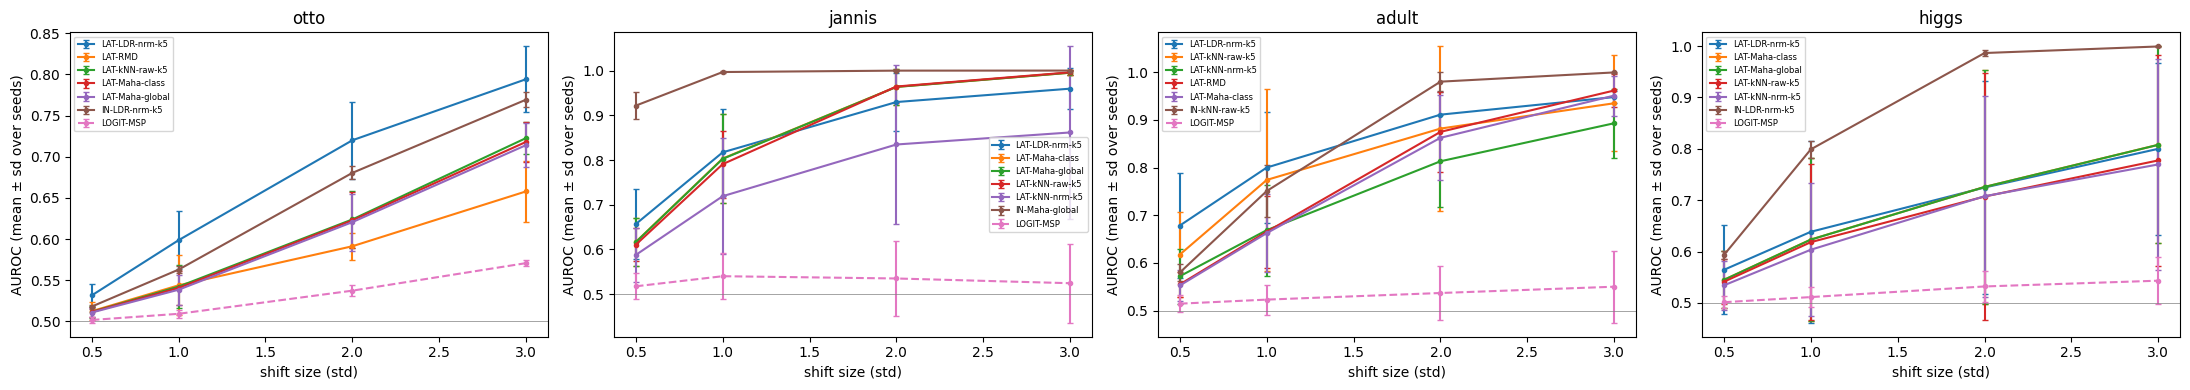


TPR at a calibrated 5% ID flag rate (mean over seeds/folds), TabM + baselines:
--- otto ---


ood,perturb_s0.5,perturb_s1.0,perturb_s2.0,perturb_s3.0,heldout,tail,tailB,mean
detector,,,,,,,,
LAT-LDR-nrm-k5,0.060,0.091,0.210,0.281,0.053,0.595,0.474,0.252
LAT-Maha-class,0.058,0.077,0.163,0.258,0.031,0.848,0.318,0.250
LAT-Maha-global,0.057,0.075,0.162,0.257,0.032,0.847,0.320,0.250
LAT-kNN-raw-k5,0.055,0.076,0.153,0.252,0.036,0.847,0.281,0.243
LAT-PCAres-r8,0.051,0.064,0.136,0.209,0.033,0.812,0.351,0.237
LAT-kNN-nrm-k5,0.053,0.069,0.104,0.175,0.162,0.759,0.320,0.234
LAT-kNN-nrm-k20,0.054,0.071,0.101,0.162,0.144,0.753,0.319,0.229
IN-Maha-global,0.052,0.062,0.116,0.255,0.070,0.852,0.190,0.228
IN-Maha-class,0.052,0.061,0.115,0.255,0.070,0.853,0.190,0.228


--- jannis ---


ood,perturb_s0.5,perturb_s1.0,perturb_s2.0,perturb_s3.0,heldout,tail,tailB,mean
detector,,,,,,,,
IN-Maha-global,0.433,1.000,1.000,1.000,0.077,0.164,0.496,0.596
IN-Maha-class,0.428,1.000,1.000,1.000,0.077,0.157,0.471,0.591
IN-kNN-raw-k5,0.091,0.312,0.996,1.000,0.089,0.137,0.418,0.435
IN-PCAres-r8,0.093,0.317,0.991,1.000,0.071,0.061,0.430,0.423
LAT-Maha-class,0.095,0.328,0.812,0.984,0.085,0.044,0.512,0.409
LAT-Maha-global,0.095,0.327,0.812,0.984,0.085,0.044,0.512,0.408
LAT-kNN-raw-k5,0.103,0.353,0.816,0.985,0.076,0.038,0.464,0.405
IN-Euc-mean-z,0.071,0.154,0.815,1.000,0.086,0.160,0.400,0.384
LOGIT-MI,0.118,0.341,0.711,0.848,0.073,0.133,0.376,0.371


--- adult ---


ood,perturb_s0.5,perturb_s1.0,perturb_s2.0,perturb_s3.0,tail,tailB,mean
detector,,,,,,,
IN-kNN-raw-k5,0.064,0.146,0.903,1.000,0.379,0.281,0.462
LAT-LDR-nrm-k5,0.162,0.314,0.545,0.710,0.474,0.457,0.443
LAT-kNN-raw-k5,0.062,0.173,0.661,0.699,0.731,0.257,0.430
LAT-kNN-nrm-k5,0.056,0.094,0.309,0.595,0.562,0.499,0.352
LAT-RMD,0.059,0.093,0.349,0.736,0.514,0.294,0.341
LAT-Maha-class,0.056,0.082,0.238,0.673,0.518,0.293,0.310
LAT-Maha-global,0.055,0.082,0.234,0.669,0.517,0.293,0.308
IN-LDR-nrm-k5,0.087,0.192,0.362,0.532,0.253,0.420,0.308
LAT-kNN-nrm-k20,0.049,0.066,0.183,0.450,0.486,0.458,0.282


--- higgs ---


ood,perturb_s0.5,perturb_s1.0,perturb_s2.0,perturb_s3.0,tail,tailB,mean
detector,,,,,,,
IN-LDR-nrm-k5,0.090,0.306,0.932,0.998,0.513,0.612,0.575
IN-kNN-raw-k5,0.073,0.184,0.889,1.000,0.406,0.656,0.535
IN-Maxabs-z,0.069,0.146,0.598,0.963,0.598,0.711,0.514
IN-Maha-class,0.068,0.185,0.736,0.979,0.387,0.684,0.507
IN-Maha-global,0.069,0.186,0.733,0.979,0.384,0.684,0.506
IN-Euc-mean-z,0.067,0.136,0.660,0.982,0.412,0.757,0.502
IN-PCAres-r8,0.067,0.155,0.650,0.903,0.382,0.461,0.436
LAT-Maha-class,0.061,0.140,0.382,0.497,0.834,0.692,0.434
LAT-Maha-global,0.061,0.140,0.382,0.497,0.833,0.692,0.434


In [19]:
import matplotlib.pyplot as plt
def dose_plot(arch='tabm', topn=5):
    dsets = CFG['datasets']; fig, axs = plt.subplots(1, len(dsets), figsize=(5.5 * len(dsets), 4), squeeze=False)
    for ax, ds in zip(axs[0], dsets):
        sub = pick(ds, arch); sub = sub[sub.proto == 'perturb'].copy(); sub['s'] = sub.ood.str.replace('perturb_s', '').astype(float)
        m = sub[sub.s == 1.0].groupby('detector').AUROC.mean().sort_values(ascending=False)
        dets = [x for x in m.index if x.startswith('LAT')][:topn] + [x for x in m.index if x.startswith('IN-')][:1] + ['LOGIT-MSP']
        for det in dets:
            g = sub[sub.detector == det].groupby(['s', 'seed']).AUROC.mean().groupby('s').agg(['mean', 'std'])
            ax.errorbar(g.index, g['mean'], yerr=g['std'], marker='o', ms=3, capsize=2, ls='--' if det.startswith('LOGIT') else '-', label=det)
        ax.axhline(0.5, color='gray', lw=0.5); ax.set_title(ds); ax.set_xlabel('shift size (std)'); ax.set_ylabel('AUROC (mean ± sd over seeds)'); ax.legend(fontsize=6)
    plt.tight_layout(); plt.savefig(f'{OUT}/dose_response.png', dpi=130); plt.show()
dose_plot('tabm')

print('\nTPR at a calibrated 5% ID flag rate (mean over seeds/folds), TabM + baselines:')
for ds in CFG['datasets']:
    t = pick(ds, 'tabm').pivot_table(index='detector', columns='ood', values='TPR05', aggfunc='mean')
    t = t[[c for c in OODCOLS if c in t.columns]]; t['mean'] = t.mean(1); print(f'--- {ds} ---'); display(t.sort_values('mean', ascending=False).head(12).round(3))

In [20]:
# Held-out classes: report EVERY fold. A mean over folds with opposite signs looks like "weak detection" but means "unreliable direction".
print('Held-out classes, AUROC per fold (mean over seeds). min / n_folds>0.5 expose sign flips; "sd" is the across-seed sd averaged over folds.\n')
FOLD = {}
for ds in CFG['datasets']:
    sub = pick(ds, 'tabm'); sub = sub[sub.proto == 'heldout']
    if sub.empty: continue
    pf = sub.groupby(['detector', 'ctx']).AUROC.mean().unstack(); folds = list(pf.columns)
    sd = sub.groupby(['detector', 'ctx']).AUROC.std().unstack().mean(1)
    pf['mean'] = pf[folds].mean(1); pf['min'] = pf[folds].min(1); pf['n>0.5'] = (pf[folds] > 0.5).sum(1); pf['sd'] = sd; FOLD[ds] = pf
    ce = CE[(CE.dataset == ds) & (CE.proto == 'heldout')].groupby('ctx').ceiling.mean().round(3).to_dict()
    print(f'=== {ds}: input-space ceiling per fold: {ce} ===')
    print(f'   detectors whose folds straddle 0.5 (sign flip): {int(((pf[folds].min(1) < 0.5) & (pf[folds].max(1) > 0.5)).sum())} of {len(pf)}')
    print('   most sign-robust (sorted by worst fold):'); display(pf.sort_values('min', ascending=False).head(10).round(3))
    print('   fixed shortlist:'); display(pf.loc[[d for d in PREREG if d in pf.index]].round(3))
pd.concat(FOLD, names=['dataset']).round(4).to_csv(f'{OUT}/summary_heldout_per_fold.csv')

Held-out classes, AUROC per fold (mean over seeds). min / n_folds>0.5 expose sign flips; "sd" is the across-seed sd averaged over folds.

=== otto: input-space ceiling per fold: {'hold0': 0.96, 'hold1': 0.935, 'hold8': 0.985} ===
   detectors whose folds straddle 0.5 (sign flip): 17 of 23
   most sign-robust (sorted by worst fold):


ctx,hold0,hold1,hold8,mean,min,n>0.5,sd
detector,,,,,,,
LOGIT-Energy,0.631,0.680,0.726,0.679,0.631,3,0.020
LOGIT-MSP,0.625,0.678,0.685,0.663,0.625,3,0.006
IN-LDR-nrm-k5,0.721,0.612,0.647,0.660,0.612,3,0.003
LOGIT-MI,0.779,0.554,0.840,0.724,0.554,3,0.008
LAT-RMD,0.668,0.491,0.518,0.559,0.491,2,0.017
LAT-LDR-nrm-k5,0.532,0.611,0.485,0.543,0.485,2,0.010
LAT-kNN-nrm-k5,0.810,0.471,0.821,0.701,0.471,2,0.009
LAT-kNN-nrm-k20,0.802,0.464,0.822,0.696,0.464,2,0.009
IN-RMD,0.540,0.478,0.438,0.486,0.438,1,0.002


   fixed shortlist:


ctx,hold0,hold1,hold8,mean,min,n>0.5,sd
detector,,,,,,,
IN-Maha-global,0.635,0.284,0.644,0.521,0.284,2,0.001
IN-kNN-nrm-k20,0.617,0.297,0.653,0.522,0.297,2,0.002
LAT-Maha-class,0.609,0.241,0.610,0.487,0.241,2,0.009
LAT-RMD,0.668,0.491,0.518,0.559,0.491,2,0.017
LAT-kNN-nrm-k20,0.802,0.464,0.822,0.696,0.464,2,0.009
LAT-LDR-nrm-k5,0.532,0.611,0.485,0.543,0.485,2,0.010
LOGIT-MSP,0.625,0.678,0.685,0.663,0.625,3,0.006
LOGIT-Energy,0.631,0.680,0.726,0.679,0.631,3,0.020
LOGIT-MI,0.779,0.554,0.840,0.724,0.554,3,0.008


=== jannis: input-space ceiling per fold: {'hold0': 0.859, 'hold1': 0.754, 'hold3': 0.869} ===
   detectors whose folds straddle 0.5 (sign flip): 21 of 23
   most sign-robust (sorted by worst fold):


ctx,hold0,hold1,hold3,mean,min,n>0.5,sd
detector,,,,,,,
LAT-RMD,0.571,0.623,0.636,0.610,0.571,3,0.012
IN-LDR-nrm-k5,0.505,0.532,0.536,0.524,0.505,3,0.002
LAT-LDR-nrm-k5,0.497,0.568,0.561,0.542,0.497,2,0.006
IN-RMD,0.578,0.487,0.520,0.528,0.487,2,0.002
LOGIT-MI,0.656,0.734,0.460,0.617,0.460,2,0.014
IN-Maxabs-z,0.460,0.521,0.617,0.532,0.460,2,0.003
IN-PCAres-r8,0.444,0.556,0.585,0.528,0.444,2,0.002
LAT-kNN-raw-k5,0.423,0.516,0.672,0.537,0.423,2,0.014
LOGIT-MSP,0.732,0.744,0.406,0.627,0.406,2,0.014


   fixed shortlist:


ctx,hold0,hold1,hold3,mean,min,n>0.5,sd
detector,,,,,,,
IN-Maha-global,0.364,0.556,0.666,0.529,0.364,2,0.002
IN-kNN-nrm-k20,0.644,0.598,0.351,0.531,0.351,2,0.001
LAT-Maha-class,0.391,0.550,0.658,0.533,0.391,2,0.011
LAT-RMD,0.571,0.623,0.636,0.610,0.571,3,0.012
LAT-kNN-nrm-k20,0.682,0.703,0.378,0.588,0.378,2,0.021
LAT-LDR-nrm-k5,0.497,0.568,0.561,0.542,0.497,2,0.006
LOGIT-MSP,0.732,0.744,0.406,0.627,0.406,2,0.014
LOGIT-Energy,0.753,0.727,0.404,0.628,0.404,2,0.006
LOGIT-MI,0.656,0.734,0.460,0.617,0.460,2,0.014


In [21]:
# Detector selection without peeking at the evaluation set.
#   oracle          : best detector chosen ON the evaluation sets themselves  -> optimistic upper bound, NOT a result
#   same_proto_dev  : heldout -> chosen on the OTHER held-out folds (leave-one-fold-out); tail -> chosen on a second, different tail feature (tailB)
#   perturb_dev     : chosen on perturb s0.5/1.0 (the old rule; shown to quantify how badly it transfers)
#   median_det      : what a randomly chosen detector in that space gets
def select_report(arch='tabm'):
    rows = []
    for ds in CFG['datasets']:
        sub = pick(ds, arch)
        for space in ('LAT', 'IN'):
            sp = sub[sub.space == space]
            if sp.empty: continue
            devp = sp[sp.ood.isin(['perturb_s0.5', 'perturb_s1.0'])].groupby('detector').AUROC.mean()
            for proto in ('heldout', 'tail'):
                tg = sp[sp.proto == proto]
                if tg.empty: continue
                per_ctx = tg.groupby(['ctx', 'detector']).AUROC.mean().unstack(0); orc = per_ctx.mean(1)
                row = dict(dataset=ds, proto=proto, space=space, oracle=orc.max(), oracle_det=orc.idxmax(), median_det=orc.median(),
                           perturb_dev=orc[devp.idxmax()], perturb_dev_det=devp.idxmax(),
                           ceiling=CE[(CE.dataset == ds) & (CE.proto == proto)].ceiling.mean())
                if proto == 'heldout' and per_ctx.shape[1] > 1:
                    row['same_proto_dev'] = np.mean([per_ctx.loc[per_ctx.drop(columns=f).mean(1).idxmax(), f] for f in per_ctx.columns])
                if proto == 'tail':
                    dt = sp[sp.proto == 'tailB'].groupby('detector').AUROC.mean()
                    if len(dt): row.update(same_proto_dev=orc[dt.idxmax()], same_proto_dev_det=dt.idxmax())
                rows.append(row)
    return pd.DataFrame(rows).round(3)

SEL = {}
for a in ('tabm', 'mlp'):
    SEL[a] = select_report(a); print(f'\n=== detector selection, arch={a} ==='); display(SEL[a])
pd.concat(SEL, names=['arch']).to_csv(f'{OUT}/summary_selection.csv')

print('\n=== Fixed shortlist (PREREG), no selection: AUROC mean over seeds, TabM ===')
pr = []
for ds in CFG['datasets']:
    sub = pick(ds, 'tabm'); sub = sub[sub.detector.isin(PREREG) & sub.proto.isin(['heldout', 'tail'])]
    pr.append(sub.groupby(['detector', 'proto']).AUROC.mean().unstack().add_prefix(f'{ds}:'))
PR = pd.concat(pr, axis=1).loc[[d for d in PREREG if d in set(R.detector)]]; display(PR.round(3)); PR.to_csv(f'{OUT}/summary_prereg.csv')

print('\n=== Noise floor: across-seed sd of AUROC for the same detector and OOD set ===')
nf = []
for ds in CFG['datasets']:
    for arch in ('tabm', 'mlp'):
        s = pick(ds, arch).groupby(['detector', 'ood', 'seed']).AUROC.mean().groupby(['detector', 'ood']).std()
        nf.append(dict(dataset=ds, arch=arch, median_sd=s.median(), p90_sd=s.quantile(0.9), max_sd=s.max()))
NF = pd.DataFrame(nf).round(3); display(NF)
print('Rule of thumb: treat differences below ~2 x median_sd as noise. For a formal test use the paired per-seed differences below.')


=== detector selection, arch=tabm ===


,dataset,proto,space,oracle,oracle_det,median_det,perturb_dev,perturb_dev_det,ceiling,same_proto_dev,same_proto_dev_det
0,otto,heldout,LAT,0.701,LAT-kNN-nrm-k5,0.503,0.543,LAT-LDR-nrm-k5,0.960,0.701,NaN
1,otto,tail,LAT,0.964,LAT-Maha-class,0.927,0.856,LAT-LDR-nrm-k5,1.000,0.856,LAT-LDR-nrm-k5
2,otto,heldout,IN,0.660,IN-LDR-nrm-k5,0.529,0.660,IN-LDR-nrm-k5,0.960,0.660,NaN
3,otto,tail,IN,0.986,IN-Maxabs-z,0.925,0.747,IN-LDR-nrm-k5,1.000,0.986,IN-Maxabs-z
4,jannis,heldout,LAT,0.610,LAT-RMD,0.535,0.542,LAT-LDR-nrm-k5,0.828,0.522,NaN
5,jannis,tail,LAT,0.626,LAT-kNN-nrm-k5,0.514,0.557,LAT-LDR-nrm-k5,1.000,0.626,LAT-kNN-nrm-k5
6,jannis,heldout,IN,0.549,IN-kNN-raw-k5,0.529,0.529,IN-Maha-global,0.828,0.409,NaN
7,jannis,tail,IN,0.733,IN-Euc-mean-z,0.570,0.694,IN-Maha-global,1.000,0.720,IN-Maxabs-z
8,adult,tail,LAT,0.931,LAT-kNN-raw-k5,0.887,0.871,LAT-LDR-nrm-k5,1.000,0.871,LAT-LDR-nrm-k5
9,adult,tail,IN,0.817,IN-LDR-nrm-k5,0.671,0.817,IN-LDR-nrm-k5,1.000,0.817,IN-LDR-nrm-k5



=== detector selection, arch=mlp ===


,dataset,proto,space,oracle,oracle_det,median_det,perturb_dev,perturb_dev_det,ceiling,same_proto_dev,same_proto_dev_det
0,otto,heldout,LAT,0.688,LAT-kNN-nrm-k5,0.559,0.563,LAT-LDR-nrm-k5,0.960,0.688,NaN
1,otto,tail,LAT,0.944,LAT-Maha-global,0.889,0.488,LAT-LDR-nrm-k5,1.000,0.488,LAT-LDR-nrm-k5
2,otto,heldout,IN,0.660,IN-LDR-nrm-k5,0.529,0.660,IN-LDR-nrm-k5,0.960,0.660,NaN
3,otto,tail,IN,0.986,IN-Maxabs-z,0.925,0.747,IN-LDR-nrm-k5,1.000,0.986,IN-Maxabs-z
4,jannis,heldout,LAT,0.628,LAT-kNN-nrm-k20,0.488,0.489,LAT-Maha-class,0.828,0.621,NaN
5,jannis,tail,LAT,0.606,LAT-Euc-mean-z,0.471,0.426,LAT-Maha-class,1.000,0.606,LAT-Euc-mean-z
6,jannis,heldout,IN,0.549,IN-kNN-raw-k5,0.529,0.529,IN-Maha-global,0.828,0.409,NaN
7,jannis,tail,IN,0.733,IN-Euc-mean-z,0.570,0.694,IN-Maha-global,1.000,0.720,IN-Maxabs-z
8,adult,tail,LAT,0.836,LAT-RMD,0.775,0.804,LAT-LDR-nrm-k5,1.000,0.836,LAT-RMD
9,adult,tail,IN,0.817,IN-LDR-nrm-k5,0.671,0.817,IN-LDR-nrm-k5,1.000,0.817,IN-LDR-nrm-k5



=== Fixed shortlist (PREREG), no selection: AUROC mean over seeds, TabM ===


proto,otto:heldout,otto:tail,jannis:heldout,jannis:tail,adult:tail,higgs:tail
detector,,,,,,
IN-Maha-global,0.521,0.968,0.529,0.694,0.674,0.803
IN-kNN-nrm-k20,0.522,0.886,0.531,0.495,0.763,0.742
LAT-Maha-class,0.487,0.964,0.533,0.512,0.889,0.963
LAT-RMD,0.559,0.716,0.610,0.393,0.877,0.828
LAT-kNN-nrm-k20,0.696,0.925,0.588,0.616,0.886,0.494
LAT-LDR-nrm-k5,0.543,0.856,0.542,0.557,0.871,0.739
LOGIT-MSP,0.663,0.582,0.627,0.602,0.650,0.549
LOGIT-Energy,0.679,0.306,0.628,0.602,0.632,0.357
LOGIT-MI,0.724,0.871,0.617,0.649,0.781,0.896



=== Noise floor: across-seed sd of AUROC for the same detector and OOD set ===


,dataset,arch,median_sd,p90_sd,max_sd
0,otto,tabm,0.006,0.036,0.112
1,otto,mlp,0.007,0.032,0.058
2,jannis,tabm,0.013,0.089,0.212
3,jannis,mlp,0.016,0.060,0.103
4,adult,tabm,0.034,0.183,0.266
5,adult,mlp,0.026,0.160,0.266
6,higgs,tabm,0.029,0.201,0.256
7,higgs,mlp,0.026,0.119,0.256


Rule of thumb: treat differences below ~2 x median_sd as noise. For a formal test use the paired per-seed differences below.


In [22]:
# TabM vs MLP embeddings. Both now use a learning rate chosen from the SAME grid by validation NLL, so the gap is no longer an lr artefact.
print('Chosen learning rates:'); display(ACC.groupby(['dataset', 'arch']).lr.first().unstack())
a = R[(R.arch == 'tabm') & (R.space == 'LAT')]; b = R[(R.arch == 'mlp') & (R.space == 'LAT')]
m = a.merge(b, on=['dataset', 'ctx', 'seed', 'detector', 'ood'], suffixes=('_tabm', '_mlp')); m['dAUROC'] = m.AUROC_tabm - m.AUROC_mlp
m['proto'] = m.ood.str.split('_').str[0]
ps = m.groupby(['dataset', 'proto', 'seed']).dAUROC.mean().reset_index()                 # seed = unit of replication
out = ps.groupby(['dataset', 'proto']).dAUROC.agg(['mean', 'std', 'count']); out['sem'] = out['std'] / np.sqrt(out['count'])
out['frac_detectors>0'] = m.groupby(['dataset', 'proto']).dAUROC.apply(lambda x: (x > 0).mean())
out['frac_seeds>0'] = ps.groupby(['dataset', 'proto']).dAUROC.apply(lambda x: (x > 0).mean())
print('\nTabM minus MLP, same detector / seed / OOD set (positive = the TabM embedding helps; count = number of seeds):')
display(out.rename(columns={'count': 'n_seeds'}).round(3)); out.round(4).to_csv(f'{OUT}/summary_tabm_vs_mlp.csv')
display(m.groupby(['detector', 'proto']).dAUROC.mean().unstack().round(3))

Chosen learning rates:


arch,mlp,tabm
dataset,,
adult,0.0003,0.001
higgs,0.0030,0.003
jannis,0.0030,0.003
otto,0.0010,0.003



TabM minus MLP, same detector / seed / OOD set (positive = the TabM embedding helps; count = number of seeds):


mean    std  n_seeds    sem  frac_detectors>0  frac_seeds>0
dataset proto                                                                
adult   perturb  0.057  0.060        3  0.035             0.808         0.667
        tail     0.123  0.019        3  0.011             0.967         1.000
        tailB    0.022  0.032        3  0.018             0.567         0.667
higgs   perturb  0.060  0.084        3  0.049             0.725         1.000
        tail     0.051  0.040        3  0.023             0.833         1.000
        tailB    0.044  0.035        3  0.020             0.700         1.000
jannis  heldout  0.031  0.006        3  0.004             0.844         1.000
        perturb  0.105  0.101        3  0.058             0.842         1.000
        tail     0.054  0.018        3  0.010             0.767         1.000
        tailB    0.179  0.038        3  0.022             0.833         1.000
otto    heldout -0.039  0.010        3  0.005             0.211         0.000
        perturb  0.021  0.001        3  0.001             0.792         1.000
        tail     0.062  0.007        3  0.004             0.933         1.000
        tailB    0.147  0.019        3  0.011             0.900         1.000

proto,heldout,perturb,tail,tailB
detector,,,,
LAT-Euc-mean-z,-0.008,0.070,0.030,-0.004
LAT-LDR-nrm-k5,0.005,0.105,0.151,0.176
LAT-Maha-class,-0.012,0.044,0.050,0.078
LAT-Maha-global,-0.010,0.044,0.049,0.078
LAT-Maxabs-z,-0.010,0.067,0.078,0.051
LAT-PCAres-r8,-0.000,0.036,0.048,0.127
LAT-RMD,0.017,0.021,-0.005,-0.054
LAT-kNN-nrm-k20,-0.015,0.078,0.113,0.197
LAT-kNN-nrm-k5,-0.009,0.088,0.117,0.197


In [23]:
# How far is each detector from the input-space ceiling? (best-of-N is optimistic: it is taken on the evaluation sets themselves)
rows = []
for ds in CFG['datasets']:
    sub = pick(ds, 'tabm')
    for (ctx, ood), cg in CE[CE.dataset == ds].groupby(['ctx', 'ood']):
        mm = sub[(sub.ctx == ctx) & (sub.ood == ood)].groupby('detector').AUROC.mean(); r = dict(dataset=ds, ctx=ctx, ood=ood, ceiling=cg.ceiling.mean())
        for spc in ('IN', 'LAT', 'LOGIT'):
            v = mm[mm.index.str.startswith(spc + '-')]; r[f'best_{spc}'] = v.max(); r[f'median_{spc}'] = v.median()
        r['gap_best'] = r['ceiling'] - np.nanmax([r['best_IN'], r['best_LAT'], r['best_LOGIT']])
        mx = mm[mm.index.isin(['IN-Maxabs-z'])]; r['IN_Maxabs-z'] = mx.iloc[0] if len(mx) else np.nan      # single-coordinate reference
        rows.append(r)
GAP = pd.DataFrame(rows).round(3); display(GAP); GAP.to_csv(f'{OUT}/summary_ceiling_gap.csv', index=False)
print('\nIf IN_Maxabs-z is close to the best detector on `tail`, that protocol is essentially a one-feature threshold test;')
print('median_* far below best_* means most detectors are far worse than the best (and best-of-N is optimistic).')

,dataset,ctx,ood,ceiling,best_IN,median_IN,best_LAT,median_LAT,best_LOGIT,median_LOGIT,gap_best,IN_Maxabs-z
0,otto,full,perturb_s0.5,1.000,0.518,0.509,0.531,0.510,0.508,0.502,0.468,0.510
1,otto,full,perturb_s1.0,1.000,0.563,0.530,0.599,0.538,0.531,0.509,0.401,0.525
2,otto,full,perturb_s2.0,1.000,0.680,0.612,0.720,0.607,0.602,0.537,0.280,0.568
3,otto,full,perturb_s3.0,1.000,0.791,0.723,0.794,0.700,0.686,0.571,0.206,0.649
4,otto,hold0,heldout,0.960,0.721,0.635,0.810,0.605,0.779,0.631,0.150,0.642
5,otto,hold1,heldout,0.935,0.612,0.298,0.611,0.389,0.680,0.678,0.255,0.299
6,otto,hold8,heldout,0.985,0.680,0.650,0.822,0.611,0.840,0.726,0.145,0.680
7,otto,tailB[feat_25],tailB,1.000,0.882,0.613,0.826,0.703,0.665,0.649,0.118,0.882
8,otto,tail[feat_11],tail,1.000,0.986,0.925,0.964,0.927,0.871,0.582,0.014,0.986
9,jannis,full,perturb_s0.5,0.999,0.922,0.573,0.657,0.582,0.601,0.518,0.078,0.549



If IN_Maxabs-z is close to the best detector on `tail`, that protocol is essentially a one-feature threshold test;
median_* far below best_* means most detectors are far worse than the best (and best-of-N is optimistic).
